<h1 align="center">Complejidad y actividad espectral del EEG a través de las etapas del sueño</h1>

<h3 align="center">Trabajo Práctico Final - Introducción a la Ingeniería de Datos</h3>

**Autor:** Ing. Matías R. Pretel  
**Profesor:** Dr. Ing. Nicolás Guillermo Tripp  
**Año:** 2026

# Declaración de uso de IA

Se utilizó Claude Code Opus 5.5 para:
- diseñar la arquitectura del pipeline ETL y los modelos OLTP y dimensional
- generar y revisar el código Python y SQL
- diseñar el dashboard

La IA no generó datos: todos los resultados provienen de la ejecución del pipeline sobre datos públicos.

**Instrucciones de la IA**

Se utilizaron instrucciones para cada etapa de la cadena de procesamiento. Antes de cada sección aparece la instrucción que la generó, con este formato:

> **Prompt N.** *texto de la instrucción*

Los prompts muestran el tipo de instrucción que se le dio a la IA en cada etapa. Sin embargo, los resultados fueron revisados y, cuando hizo falta, adaptados o modificados manualmente. En este documento no se muestran todos los prompts utilizados, hay muchos prompts relacionados con correcciones o generación de gráficos que no se presentan. Solamente se pusieron los prompt que terminaron generando gran parte del código.

## Objetivo

Construir un pipeline de datos reproducible que:

1. descarga automáticamente EEG de sueño público (EDF/EDF+);
2. lo organiza en formato BIDS;
3. lo transforma en épocas de 30 s etiquetadas con su etapa de sueño;
4. calcula métricas espectrales y de complejidad por época y canal;
5. detecta y documenta outliers estadísticos y artefactos de señal;
6. carga los resultados en una base SQLite transaccional normalizada (3NF);
7. construye un Data Warehouse en esquema estrella y lo consulta con SQL;
8. comunica los resultados con visualizaciones usando Plotly y un dashboard con Streamlit.

## Preguntas de investigación

> **1. ¿Cómo varían la complejidad y la actividad espectral del EEG entre las distintas etapas del sueño?**
>
> **2. ¿Cómo difiere la potencia sigma en N2 entre personas de distintas edades?**

- **Actividad espectral**: potencia absoluta y relativa en las bandas de interés (delta, theta, alfa, sigma y beta).
- **Complejidad**: Sample Entropy (impredecibilidad temporal de la señal).

**Aclaración:** No se realizaron tests de hipótesis, todos los resultados son descriptivos, por lo que una diferencia observada no implica significancia estadística, y una asociación no implica causalidad.

## Dataset

Se utilizó el dataset público **Sleep-EDF Expanded** (Kemp et al., 2000; PhysioNet, DOI [10.13026/C2X676](https://doi.org/10.13026/C2X676)),
subconjunto *sleep-cassette* (SC): polisomnografías ambulatorias de ~21–24 h de personas sanas sin medicación.

A continuación se describe el contenido del dataset.

| Elemento | Descripción |
|---|---|
| `SC4ssN?0-PSG.edf` | Polisomnografía: EEG Fpz-Cz y Pz-Oz (100 Hz), EOG (100 Hz), EMG, respiración, temperatura (1 Hz) |
| `SC4ssN??-Hypnogram.edf` | Etapas de sueño anotadas por expertos (reglas de Rechtschaffen & Kales) en segmentos múltiplos de 30 s |
| `SC-subjects.xls` | Edad, sexo y hora de apagado de luces por sujeto y noche |
| `SHA256SUMS.txt` | Lista de archivos con sus hashes |

`ss` = sujeto, `N` = noche.

**Selección de sujetos:** se procesan 2 noches por sujeto, con la misma cantidad de mujeres y de hombres en cada
grupo etario (<40, 40–64 y 65+). La cantidad la fija `SUBJECTS_PER_GROUP` en `src/config.py` (con 3 por grupo,
18 sujetos). La elección la hace el código, con una regla que usa solo edad, sexo y cantidad de noches, sin mirar las
señales; la tabla con los sujetos elegidos se genera en la sección *Extract*.

El ID es el número de sujeto de Sleep-EDF: por ejemplo, el sujeto 4 corresponde a los archivos `SC4041…` (noche 1)
y `SC4042…` (noche 2).

Aclaración: El dataset no cuenta con sujetos de 35 a 49 años, de 61 a 65 ni de 75 a 84.

**Consideraciones de diseño:**

| Decisión | Motivo |
|---|---|
| Recortar la vigilia | Sin el recorte, W domina el análisis. Solo se conservan los despertares durante la noche y los 30 minutos antes de dormirse y 30 minutos después de despertarse |
| Muestra estratificada por sexo y edad | Para comparar edades hacen falta grupos del mismo tamaño y con ambos sexos |
| Detectar artefactos con criterios físicos en lugar de un umbral de amplitud | **Señal plana**: desvío estándar de la época menor a 0,5 µV, compatible con un electrodo desconectado. **Saturación**: al menos 10 muestras (0,1 s) pegadas al límite físico del EDF, contadas sobre la señal sin filtrar |
| Marcar outliers con Tukey dentro de cada noche | Tukey se aplica a 7 métricas (amplitud, potencias y Sample Entropy), comparando cada época con las de su misma noche, canal y etapa, porque cada persona tiene su propia amplitud y espectro. |
| Usar 3 dimensiones en el almacén: registro, canal y etapa | El sujeto y su grupo etario van dentro de la dimensión registro, porque cada noche pertenece a un solo sujeto. Las 3 dimensiones forman el cubo etapa × grupo etario × canal |


## Arquitectura general del proyecto

A continuación se describen los módulos utilizados en este proyecto.

| Módulo | Responsabilidad |
|---|---|
| `config.py` | Rutas relativas, selección de sujetos, parámetros metodológicos y umbrales |
| `extract.py` | Catálogo, selección, descarga validada y manifest |
| `bids.py` | Conversión a BIDS y metadatos |
| `preprocessing.py` | Lectura EDF, validación, épocas, recorte de vigilia, filtrado |
| `features.py` | Métricas espectrales y de complejidad |
| `quality.py` | Artefactos y outliers de Tukey |
| `pipeline.py` | Procesa cada registro (filtrado, épocas y features) y reutiliza los ya calculados |
| `database_oltp.py` / `database_dw.py` | Bases SQLite transaccional y analítica |
| `queries.py` / `plots.py` | Consultas SQL y figuras (compartidas con el dashboard) |
| `validation.py` | Verifica que los datos no se pierdan, dupliquen ni corrompan entre la tabla tidy, el OLTP y el DW |
| `dashboard.py` | Dashboard con Streamlit |

**Nota:** El archivo con las versiones de las librerías utilizadas "requirements.txt" se fue actualizando a medida que se fue avanzando con el proyecto. Una ves terminado el trabajo, se eliminaron las librerías que no se utilizaron.

## Configuración del proyecto

La primera celda prepara el entorno, que puede trabajar de forma local o desde Google Colab. En Google Colab, clona el repositorio, se ubica en la carpeta `TP/tpf` e instala las dependencias; localmente
solo agrega la raíz del proyecto al `sys.path`. Todas las rutas se calculan relativas a la raíz con `pathlib`.

> **Prompt 0.** *Tomá el rol de ingeniero de datos con experiencia en EEG del sueño. La idea es armar un pipeline con el dataset público Sleep-EDF Expanded de PhysioNet. El objetivo es responder dos preguntas: cómo varían la complejidad y la actividad espectral del EEG entre las etapas del sueño, y cómo difiere la potencia sigma en N2 entre personas de distintas edades. El pipeline de procesamiento será el siguiente:*
>
> - Descargar por código los registros del dataset
> - Extraer las señales de los registros y separarlas en épocas de 30 s con su etapa de sueño
> - Calcular métricas espectrales y de complejidad
> - Hacer un control de calidad de las señales
> - Cargar las métricas en una base de datos SQLite normalizada, y crear un almacén en esquema estrella y por último un dashboard.
>
> Consideraciones:
> - Todo tiene que correr desde este notebook, en Colab o de forma local, sin rutas locales ni carga manual, y el repositorio va a mantener solo los directorios "data", "notebooks", "src" y un documento de texto "README.md".
> - No tomes ninguna acción por el momento.

> **Prompt 1.** *El notebook tiene que correr tanto en Colab como en forma local, sin que haya que configurar nada. Si está en Colab, que clone el repo de GitHub, instale lo que está en "requirements.txt" y se pare en la carpeta del proyecto. Si es local, que encuentre solo la raíz del proyecto, aunque lo abra desde la carpeta "notebooks". No usar rutas fijas.*

In [1]:
import os, sys, subprocess
from pathlib import Path

# Repositorio público de la materia: en Colab se clona desde acá. El trabajo está en TP/tpf.
REPO_URL = "https://github.com/Mpretel/IID_MP.git"
PROJECT_SUBDIR = Path("TP") / "tpf"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    repo_dir = Path("/content") / Path(REPO_URL).stem
    if not repo_dir.exists():
        subprocess.run(["git", "clone", REPO_URL, str(repo_dir)], check=True)
    PROJECT_ROOT = repo_dir / PROJECT_SUBDIR
    os.chdir(PROJECT_ROOT)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
else:
    PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print("Raíz del proyecto:", PROJECT_ROOT)

Raíz del proyecto: C:\workspace\IID_MP\TP\tpf


> **Prompt 2.** *Ahora armá una celda que deje el entorno listo: que las tablas se vean bien sin llenar la pantalla, que MNE no llene la salida con mensajes y que los resultados sean siempre los mismos (usar única seed). Y al final mostrame un resumen con los parámetros, así queda registrado con qué se corrió todo.*

In [2]:

import logging, random
import numpy as np
import pandas as pd

# Parámetros del proyecto
from src import config
# MNE tira mucha información por pantalla, así que se silencia un poco (solo warnings y errores)
logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s", force=True)
logging.getLogger("mne").setLevel(logging.WARNING)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 20)  # tablas de más de 20 filas: se muestran las primeras y últimas 5

random.seed(config.RANDOM_SEED)
np.random.seed(config.RANDOM_SEED)


# Se imprime en pantalla la configuración de ejecución
print("Sujetos por grupo etario y sexo:", config.SUBJECTS_PER_GROUP, "| noches:", config.NIGHTS)
print("Canales EEG:", config.EEG_CHANNELS)
print("Época:", config.EPOCH_DURATION_S, "s | filtro:", config.L_FREQ_HZ, "-", config.H_FREQ_HZ, "Hz",
      "| vigilia conservada:", config.WAKE_PADDING_MIN, "min de cada lado")
print("Bandas:", config.FREQ_BANDS)
print("Umbrales de artefacto: ≥", config.ARTIFACT_MIN_CLIPPED_SAMPLES, "muestras saturadas; SD <", config.ARTIFACT_MIN_STD_UV, "µV")

Sujetos por grupo etario y sexo: 3 | noches: (1, 2)
Canales EEG: ['EEG Fpz-Cz', 'EEG Pz-Oz']
Época: 30.0 s | filtro: 0.5 - 30.0 Hz | vigilia conservada: 30 min de cada lado
Bandas: {'delta': (0.5, 4.0), 'theta': (4.0, 8.0), 'alpha': (8.0, 12.0), 'sigma': (12.0, 16.0), 'beta': (16.0, 30.0)}
Umbrales de artefacto: ≥ 10 muestras saturadas; SD < 0.5 µV


> **Prompt 3.** *Para poder comparar edades, armá una muestra estratificada con la misma cantidad de mujeres y de hombres en cada grupo etario (<40, 40 a 64 y >64). Que la cantidad se pueda configurar; por ahora, 3 de cada sexo por grupo. Elegí los sujetos con una regla que use solo edad, sexo y cantidad de noches, sin mirar sus señales.*

> **Prompt 4.** *Armá la extracción de Sleep-EDF Expanded: PSG e hipnogramas de los sujetos de la muestra, 2 noches cada uno. Verificá cada archivo con su checksum para asegurarte de que se haya descargado correctamente y guardá un manifest. Que la descarga sea robusta: si falla, que reintente, y si se corta, que no queden archivos basura. Lo que ya esté bajado y verificado que no se descargue de nuevo*

## Extract

Los registros se descargan de PhysioNet y se guardan sin modificar en `data/raw/`.

1. **Catálogo de archivos.** Se descarga `SHA256SUMS.txt`, el archivo de PhysioNet que lista cada archivo del dataset con su hash. Con ese archivo se arma el catálogo de registros, emparejando cada PSG con su hipnograma por sujeto y noche.
2. **Muestra de sujetos.** `extract.select_subjects` elige la muestra estratificada, con `config.SUBJECTS_PER_GROUP` mujeres y hombres por grupo etario.
3. **Descarga de registros.** Se bajan el PSG y el hipnograma de cada registro y se verifica su hash. Si la descarga se corta, no quedan archivos a medias, y lo que ya está descargado y verificado no se vuelve a bajar.
4. **Manifest.** Cada archivo queda anotado en `data/raw/download_manifest.csv`, con su tamaño, su hash, la URL de origen y la fecha en que se verificó.

In [3]:
from IPython.display import display
from src import extract, bids

catalog = extract.build_catalog(extract.fetch_checksums())
print(f"Catálogo sleep-cassette: {len(catalog)} registros de {catalog['subject'].nunique()} sujetos")
print("Sujetos con una sola noche:", sorted(catalog.groupby("subject")["night"].count().loc[lambda s: s < 2].index))

# Muestra estratificada elegida por código.
SUBJECTS = extract.select_subjects(config.SUBJECTS_PER_GROUP)
manifest = extract.run_extract(SUBJECTS)

# Muestra: sujeto (edad) por grupo etario y sexo, según SC-subjects.xls
sample = bids.load_subjects_metadata().drop_duplicates("subject")
sample = sample[sample["subject"].isin(manifest["subject"])].sort_values("age")
sample["grupo etario"] = pd.cut(sample["age"], config.AGE_BINS, right=False, labels=config.AGE_LABELS)
sample["sujeto (edad)"] = sample["subject"].astype(str) + " (" + sample["age"].astype(str) + ")"
display(sample.pivot_table(index="grupo etario", columns="sex", values="sujeto (edad)", aggfunc=", ".join,
                           observed=True).rename(columns={"F": "Mujeres", "M": "Hombres"}).rename_axis(columns=None))

INFO src.extract: Registros seleccionados: 36 (18 sujetos)


Catálogo sleep-cassette: 153 registros de 78 sujetos
Sujetos con una sola noche: [13, 36, 52]


INFO src.extract: Archivos: 72 (72 en caché, 0 descargados)


,Mujeres,Hombres
grupo etario,,
<40,"5 (28), 6 (31), 4 (34)","10 (26), 14 (27), 16 (32)"
40-64,"20 (51), 24 (54), 22 (56)","38 (51), 31 (54), 33 (60)"
65+,"40 (67), 65 (88), 61 (101)","50 (71), 76 (90), 73 (97)"


> **Prompt 5.** *Organizá los registros en BIDS con MNE-BIDS, sin tocar los datos crudos.*

## Organización BIDS

El EDF (European Data Format) es un formato estandarizado que define cómo se almacenan las señales electrofisiológicas y la información asociada a cada registro, incluida en su encabezado.

Por otro lado, BIDS (Brain Imaging Data Structure) es un estándar que establece cómo organizar y documentar conjuntos de datos (datasets) de neuroimágenes y registros electrofisiológicos. A diferencia de EDF, BIDS no define cómo se almacenan las señales dentro de un archivo, sino cómo se organizan los archivos y sus metadatos. De esta manera, permite conservar los registros EDF originales dentro de una estructura estandarizada.

La organización de BIDS se basa en tres principios fundamentales:

1) Estructura jerárquica de carpetas: los datos se organizan por sujeto, sesión (si corresponde) y tipo de registro. Por ejemplo: sub-04/ses-1/eeg/.

2) Nombres de archivos estandarizados: se utilizan pares clave-valor que permiten identificar el contenido sin necesidad de abrir el archivo. Por ejemplo, sub-04_ses-1_task-sleep_eeg.edf identifica el sujeto, la sesión, la tarea y el tipo de registro.

3) Metadatos estructurados: la información complementaria se almacena en archivos TSV (tablas) y JSON (descripciones), que pueden ser interpretados tanto por personas como por programas.

La principal ventaja de BIDS es que proporciona una estructura consistente y documentada, facilitando la comprensión, el intercambio y el procesamiento automático de los datos mediante herramientas compatibles con BIDS, como MNE-BIDS o EEGLAB.

In [4]:
bids.run_bids(manifest)

INFO src.bids: BIDS: 36 registros de 18 sujetos en data/bids


> **Prompt 6.** *Antes de procesar las señales, verificá que cada registro tenga los canales, la frecuencia de muestreo correcta y las unidades esperadas, y que el hipnograma coincida con la señal. Si algo no se cumple, que el pipeline se detenga y diga qué falló y por qué.*

## Exploración inicial

Antes de procesar se inspecciona cada registro utilizando el header de los archivos EDF: canales, frecuencia de muestreo, unidades,
duración y coherencia entre PSG e hipnograma. "validate_recording" detiene el pipeline si un registro no cumple lo esperado, por ejemplo:

- falta alguno de los canales EEG (Fpz-Cz o Pz-Oz);
- la frecuencia de muestreo del EEG no es 100 Hz o las unidades no son µV;
- el PSG y el hipnograma no empiezan a la misma hora (las etapas quedarían desfasadas de la señal);
- alguna anotación del hipnograma no dura un múltiplo de 30 s, o tiene una etiqueta que no está en el mapeo de etapas.

In [5]:
from src import preprocessing

# Una fila por registro con las rutas de sus dos archivos (columnas PSG y Hypnogram).
files = manifest.pivot(index="recording_id", columns="kind", values="file").reset_index()
infos, warnings_found = [], []
for psg, hyp in zip(files["PSG"], files["Hypnogram"]):
    # Lee solo el encabezado y las anotaciones; validate_recording corta si algo es inesperado.
    info = preprocessing.inspect_recording(config.PROJECT_ROOT / psg, config.PROJECT_ROOT / hyp)
    warnings_found += preprocessing.validate_recording(info)
    infos.append(info)

hours = [i["psg_duration_s"] / 3600 for i in infos]
print(f"{len(infos)} registros validados · PSG de {min(hours):.1f} a {max(hours):.1f} h · "
      f"EEG a {config.EXPECTED_SFREQ_HZ:.0f} Hz y en µV")
print("Canales del PSG:", info["channels"])
print("Prefiltro de adquisición EEG:", info["eeg_prefilter"])
print(f"Advertencias: {len(warnings_found)}. Ejemplo:")
for w in warnings_found[:1]:
    print("  -", w)

36 registros validados · PSG de 21.0 a 23.8 h · EEG a 100 Hz y en µV
Canales del PSG: ['EEG Fpz-Cz', 'EEG Pz-Oz', 'EOG horizontal', 'Resp oro-nasal', 'EMG submental', 'Temp rectal', 'Event marker']
Prefiltro de adquisición EEG: {'EEG Fpz-Cz': 'HP:0.5Hz LP:100Hz [enhanced cassette BW]', 'EEG Pz-Oz': 'HP:0.5Hz LP:100Hz [enhanced cassette BW]'}
Advertencias: 36. Ejemplo:
  - SC4041E0-PSG.edf: el hipnograma termina en 86400 s y la señal en 77100 s; las épocas sin señal se descartan al segmentar


Con esta validación vemos que todos los registros tienen los dos canales EEG a 100 Hz y en µV. En todos, el hipnograma se extiende más allá del final
de la señal: esas épocas no tienen señal y se descartan. Esto es porque el hipnograma se hizo en una ventana fija de 24 hs, mientras que la señal registrada tiene una duración menor a 24 hs.

> **Prompt 7.** *Segmentá en épocas de 30 s y pasá las etapas del hipnograma (criterio R&K) a AASM (juntando S3 y S4 en N3). Si hay épocas que el experto no pudo puntuar (por movimiento o etapa desconocida), conservalas sin imputar. Recortá la vigilia a 30 min antes y después del sueño nocturno para que no domine el análisis y, por último, filtrá las señales de 0,5 a 30 Hz.*

## Transform

Cada registro se procesa por separado, para no tener varias señales en memoria:

1. **Épocas:** el hipnograma se divide en épocas de 30 s.
2. **Recorte de vigilia:** los registros duran entre 21 y 24 h y casi todo es vigilia diurna. Se conservan 30 min de W antes y después del sueño nocturno. Las épocas recortadas no se borran: quedan marcadas.
3. **Filtro pasa banda 0,5–30 Hz** (FIR de fase cero) sobre la señal. Con este rango de frecuencias se elimina la deriva lenta y atenúa la actividad muscular y ruido de red.
4. **Features y marcas de artefacto** por época y canal, guardadas en Parquet por registro. Son 14 features (definidas en *Extracción de features*):
   - **Espectrales:** potencia absoluta y relativa de cada banda (delta, theta, alfa, sigma y beta) y potencia total.
   - **Complejidad:** Sample Entropy.
   - **Amplitud:** RMS y pico a pico.

   Las marcas de artefacto indican si la señal de esa época está plana o saturada.

En el paso 1, las etiquetas originales del hipnograma (R&K) se mapean a la nomenclatura AASM:

| Hipnograma | Etapa | Tratamiento |
|---|---|---|
| `Sleep stage W` | W | Puntuada |
| `Sleep stage 1` | N1 | Puntuada |
| `Sleep stage 2` | N2 | Puntuada |
| `Sleep stage 3`, `Sleep stage 4` | N3 | Puntuada (R&K S3 + S4 = AASM N3) |
| `Sleep stage R` | REM | Puntuada |
| `Movement time` | MOVE | No es una etapa de sueño: se conserva, no se imputa |
| `Sleep stage ?` | UNK | Desconocida: se conserva, no se imputa |

NOTA: Las etapas MOVE y UNK no se reasignan a una etapa y no se cargan en las bases de datos.

> **Prompt 8.** *Por época y canal calculá potencia absoluta y relativa por banda con Welch, Sample Entropy, RMS y pico a pico, y marcá los artefactos (señal plana o más de 500 µV de pico a pico) sin borrarlos. Usá librerías mantenidas, cargá solo lo necesario para no gastar memoria y dejá el resultado como tidy data en formato Parquet.*

## Extracción de features

Para cada época de 30 s (3000 muestras a 100 Hz) y cada canal:

| Feature | Definición | Unidad | Implementación |
|---|---|---|---|
| PSD | Welch: ventana Hann de 4 s, 50 % de solapamiento. Resolución 0,25 Hz | µV²/Hz | `scipy.signal.welch` |
| Potencia absoluta de banda | $P_b = \sum_{f_1 \le f < f_2} \mathrm{PSD}(f)\,\Delta f$ en delta 0,5–4, theta 4–8, alfa 8–12, sigma 12–16 y beta 16–30 Hz | µV² | `features.band_powers` |
| Potencia total y relativa | $P_{tot}$ = suma de las 5 bandas; relativa = $P_b / P_{tot}$ | µV² / — | `features.band_powers` (total) y `features.compute_features` (relativa) |
| Sample Entropy | $-\ln(A/B)$ con $m = 2$ y $r = 0{,}2\,\mathrm{SD}$ | — | `antropy.sample_entropy` |
| RMS y pico a pico | Amplitud de la señal | µV | NumPy |

- La potencia absoluta depende de la amplitud de cada sujeto y del método de integración; la relativa describe la forma del espectro y es comparable entre sujetos.
- Sample Entropy mide cuán predecible es la forma de onda: cuanto más baja, más regular es la señal.

### Carga optimizada

- **Elección de columnas:** cada EDF tiene 7 canales, y se cargan solo los 2 de EEG, para ahorrar memoria.
- **Tipo de variables:** las épocas se guardan en "float32", porque 24 h de señal en "float64" no se justifican para datos de 12 bits. Las características (features) se calculan en "float64", para no acumular error de redondeo.
- **Tabla tidy:** "sleep_stage" y "channel" se guardan como categóricas. La tabla se escribe en formato Parquet porque conserva los tipos al volver a leerla (categóricas, booleanos, float64) y comprime por columna.

**Ejecución del Transform.** La siguiente celda procesa todos los registros de la muestra y arma la tabla tidy. Los registros ya procesados se leen del caché.

In [6]:
from src import pipeline

results = pipeline.run_pipeline(manifest)
tidy, epochs, recordings = results["tidy"], results["epochs"], results["recordings"]
print(f"Tabla tidy: {tidy.shape[0]:,} filas × {tidy.shape[1]} columnas, "
      f"{tidy.memory_usage(deep=True).sum() / 1e6:.1f} MB en memoria")
n_epochs = len(tidy[["recording_id", "epoch_number"]].drop_duplicates())
print(f"Épocas analizadas: {n_epochs:,} ({n_epochs * config.EPOCH_DURATION_S / 3600:.1f} h)")

INFO src.pipeline: Tidy: 83192 filas x 26 columnas (26.4 MB en memoria)


Tabla tidy: 83,192 filas × 26 columnas, 26.4 MB en memoria
Épocas analizadas: 41,596 (346.6 h)


## Tidy Data

Cada fila es una observación (una época de 30 s de un canal EEG) y cada columna, una variable. Las épocas
completas del hipnograma y los registros van en tablas aparte. Todo se guarda en formato Parquet.

In [7]:
display(tidy.head(3))
dtypes = tidy.dtypes.astype(str)
for dtype, cols in dtypes.groupby(dtypes):
    print(f"{dtype:9} {len(cols):2} columnas: {', '.join(cols.index)}")
print(f"\nMemoria: {tidy.memory_usage(deep=True).sum() / 1e6:.1f} MB · "
      f"Parquet: {pipeline.TIDY_PATH.stat().st_size / 1e6:.1f} MB")

,subject_id,recording_id,night,epoch_number,start_time_sec,sleep_stage,stage_original,channel,delta_abs,theta_abs,alpha_abs,sigma_abs,beta_abs,delta_rel,theta_rel,alpha_rel,sigma_rel,beta_rel,total_power,sample_entropy,rms,peak_to_peak,is_artifact,artifact_reason,is_stat_outlier,outlier_features
0,4,SC4041,1,752,22560.0,W,Sleep stage W,EEG Fpz-Cz,160.041275,22.947237,7.292657,5.880720,13.561372,0.763107,0.109417,0.034773,0.028040,0.064663,209.723261,1.135260,14.792988,115.368408,False,None,False,None
1,4,SC4041,1,752,22560.0,W,Sleep stage W,EEG Pz-Oz,7.203409,6.687294,2.611215,1.119863,2.541609,0.357252,0.331655,0.129503,0.055539,0.126051,20.163390,1.618146,4.558993,37.818740,False,None,False,None
2,4,SC4041,1,753,22590.0,W,Sleep stage W,EEG Fpz-Cz,209.694342,44.913856,7.225909,4.489356,12.433262,0.752249,0.161122,0.025922,0.016105,0.044603,278.756726,0.892456,18.472021,182.236946,False,None,False,None


bool       2 columnas: is_artifact, is_stat_outlier
category   2 columnas: sleep_stage, channel
float64   15 columnas: start_time_sec, delta_abs, theta_abs, alpha_abs, sigma_abs, beta_abs, delta_rel, theta_rel, alpha_rel, sigma_rel, beta_rel, total_power, sample_entropy, rms, peak_to_peak
int64      3 columnas: subject_id, night, epoch_number
object     4 columnas: recording_id, stage_original, artifact_reason, outlier_features

Memoria: 26.4 MB · Parquet: 11.7 MB


## Hipnograma y épocas

Cantidad de épocas analizadas en cada etapa y el hipnograma de un registro de ejemplo.

In [8]:
# Épocas analizadas por etapa (solo las 5 etapas puntuadas, que son las que se comparan)
analyzed = epochs[epochs["has_signal"] & epochs["in_analysis_window"]]
counts = analyzed["stage"].value_counts().reindex(config.SCORED_STAGES)
# % sobre el total de épocas analizadas con etapa asignada (las 5 etapas suman 100 %; MOVE y UNK no entran)
display(pd.DataFrame({"épocas": counts, "%": (100 * counts / counts.sum()).round(1)}))
scored = epochs[epochs["has_signal"] & epochs["stage"].isin(config.SCORED_STAGES)]
print(f"Sin el recorte de vigilia, W sería el {100 * (scored['stage'] == 'W').mean():.1f} % de las épocas")

,épocas,%
stage,,
W,11261,27.2
N1,4030,9.7
N2,16641,40.2
N3,2610,6.3
REM,6855,16.6


Sin el recorte de vigilia, W sería el 68.6 % de las épocas


In [9]:
from src import plots

obs_preview = tidy.rename(columns={"sleep_stage": "stage_code", "start_time_sec": "start_sec"})
obs_preview["channel"] = obs_preview["channel"].astype(str).str.replace("EEG ", "")
onset = (obs_preview[obs_preview["stage_code"].isin(["N1", "N2", "N3", "REM"])]
         .groupby("recording_id")["start_sec"].min())
obs_preview["hours_since_sleep_onset"] = (obs_preview["start_sec"] - obs_preview["recording_id"].map(onset)) / 3600
obs_preview["stage_code"] = obs_preview["stage_code"].astype(str)
plots.hypnogram(obs_preview, files.iloc[0].recording_id).show()

> **Prompt 9.** *Agregá validaciones automáticas que frenen con un mensaje claro si algo falla: en la tabla tidy, en la base transaccional y en el almacén. Fijate que no se pierdan ni se dupliquen filas entre una etapa y otra.*

## Control de calidad

Sobre la tabla resultante se verifica que:

- no haya claves compuestas duplicadas: cada fila es una época de un canal de un registro, y esa combinación (registro, época, canal) no puede aparecer dos veces;
- cada época tenga ambos canales;
- la potencia relativa sume 1;
- las marcas de artefacto sean coherentes;
- no haya features NaN en filas sin artefacto.

In [10]:
from src import validation
def show_checks(lines):
    """Muestra el resultado de un bloque de validaciones (cada una lanza ValidationError si falla)."""
    for line in lines:
        print("  ✔", line)

show_checks(validation.validate_tidy(tidy))

  ✔ Sin claves (registro, época, canal) duplicadas
  ✔ Cada época tiene todos los canales
  ✔ Potencia relativa en [0, 1] y suma 1 ± 1e-09 (sin artefactos)
  ✔ is_artifact coherente con artifact_reason
  ✔ Sin features NaN en filas sin artefacto


> **Prompt 10.** *Reemplazá el umbral de 500 µV por un criterio de saturación, porque el rango físico del EDF no permite alcanzarlo. Además, marcá los outliers con Tukey, pero calculado dentro de cada noche, canal y etapa, para que marque épocas raras. Que solo los marque pero sin borrar nada.*

## Tratamiento de outliers y artefactos

Se distinguen dos tipos de épocas problemáticas. Ninguna se elimina: solo se marcan.

- **Artefacto:** la señal no refleja actividad cerebral, por ejemplo porque el electrodo se despegó o el amplificador se saturó. Se detecta con criterios físicos sobre la señal (señal plana, saturación o valores no finitos) y se marca con `is_artifact`. Estas épocas quedan fuera de los análisis.
- **Outlier estadístico:** la señal es válida, pero algún valor es extremo comparado con las demás épocas de la misma noche, canal y etapa, por ejemplo una onda lenta muy grande en N3. Se detecta con la regla de Tukey y se marca con `is_stat_outlier`. Estas épocas sí se usan en los análisis, porque pueden ser actividad real.

Las dos subsecciones siguientes explican cada criterio.

### Saturación: por qué reemplazó al umbral de amplitud

Cada canal de un EDF tiene un rango físico máximo, definido en su encabezado. Si la señal lo supera, queda recortada en ese límite. Por eso, una época se marca como saturada cuando tiene al menos 10 muestras en el límite. Se cuentan sobre la señal sin filtrar, porque el filtro suaviza los recortes y ya no quedan exactamente en el límite.

In [11]:
# Límites físicos del EEG según el encabezado de cada EDF
limits = pd.concat([preprocessing.read_edf_header(config.PROJECT_ROOT / psg)[1] for psg in files["PSG"]])
limits = limits[limits["label"].isin(config.EEG_CHANNELS)][["physical_min", "physical_max"]].astype(float)
print(f"Límite físico del EEG: de {limits.abs().min().min():.0f} a {limits.abs().max().max():.0f} µV en valor absoluto; "
      f"rango máximo de {(limits['physical_max'] - limits['physical_min']).max():.0f} µV de pico a pico")

is_clipped = tidy["artifact_reason"].eq("clipped")
print(f"Pico a pico máximo tras el filtro: {tidy['peak_to_peak'].max():.0f} µV")
print(f"Filas saturadas: {is_clipped.sum()} ({100 * is_clipped.mean():.2f} %)")
stages = tidy["sleep_stage"].astype(str)
per_stage = stages[is_clipped].value_counts()
print("Por etapa:", {s: f"{per_stage[s]} de {n}" for s, n in stages.value_counts().items() if s in per_stage})
print("Por registro:", tidy.loc[is_clipped, "recording_id"].value_counts().head(5).to_dict())

Límite físico del EEG: de 147 a 248 µV en valor absoluto; rango máximo de 424 µV de pico a pico
Pico a pico máximo tras el filtro: 437 µV
Filas saturadas: 173 (0.21 %)
Por etapa: {'N2': '28 de 33282', 'W': '115 de 22522', 'REM': '15 de 13710', 'N1': '7 de 8060', 'N3': '2 de 5220', 'MOVE': '6 de 78'}
Por registro: {'SC4201': 36, 'SC4162': 35, 'SC4061': 24, 'SC4161': 19, 'SC4651': 17}


**Corrección del criterio.** Al principio el pipeline usaba un umbral de 500 µV de pico a pico y no encontraba ningún artefacto. El problema era que el rango físico del EDF no permite superar 424 µV de pico a pico (437 µV después del filtro), así que el umbral nunca se alcanzaba. Se reemplazó por el criterio de saturación, que marca 173 filas (0,21 %). De ellas, 115 son de W, lo que es esperable por los movimientos, y solo 2 de las 5 220 filas de N3. Estas filas conservan sus features, pero se excluyen por defecto de los análisis.

### Outliers de Tukey dentro de cada registro

La regla clásica de Tukey marca como outlier todo valor fuera de [Q1 − 1,5·IQR, Q3 + 1,5·IQR], con los cuartiles
calculados sobre todos los datos. En EEG de sueño no sirve tal cual, la amplitud y el espectro cambian mucho entre
etapas y entre personas, y una regla global marcaría etapas o personas enteras en lugar de épocas raras. Por eso se
aplica a 7 variables con cuatro ajustes:

1. **Grupo de referencia:** los cuartiles se calculan dentro de cada **registro × canal × etapa**. Es la misma forma
   de agrupar que usan Ujma et al. (2025), que buscan épocas atípicas por participante, canal y estado de sueño, y
   va en línea con von Ellenrieder et al. (2022), que fijan los límites con el IQR de cada noche.
2. **Escala log10** para la potencia absoluta delta y la potencia total, porque su distribución es muy asimétrica.
3. **Cuartiles sin artefactos:** las épocas saturadas no participan del cálculo de los límites.
4. **Factor 1,5 y marca informativa:** se mantiene el factor clásico porque las épocas marcadas no se eliminan. Los    trabajos citados usan límites más amplios (por ejemplo, mediana ± 2,5 IQR en von Ellenrieder et al., 2022) porque ahí la marca sí descarta épocas.

La siguiente tabla muestra el % de épocas marcadas en cada variable y etapa. El gráfico muestra un registro de ejemplo, con un panel por variable, los puntos negros son las épocas marcadas.

La marca `is_stat_outlier` se guarda en el almacén (ver *Data Warehouse*); acá se calcula sobre la tabla tidy solo para mostrarla.

**Referencias**

- von Ellenrieder, N., Peter-Derex, L., Gotman, J., & Frauscher, B. (2022). SleepSEEG: automatic sleep scoring using
  intracranial EEG recordings only. *Journal of Neural Engineering*, 19(2). https://doi.org/10.1088/1741-2552/ac6829
- Ujma, P. P., Dresler, M., & Bódizs, R. (2025). Comparing manual and automatic artifact detection in sleep EEG
  recordings. *Psychophysiology*, 62(2), e70016. https://doi.org/10.1111/psyp.70016

In [12]:
from src import quality

# % de épocas marcadas por variable y etapa (marcas calculadas dentro de cada registro × canal × etapa)
display(quality.tukey_rate_by_metric(tidy))

# Ejemplo: cada variable en un registro y canal; los puntos negros son las épocas marcadas
example = quality.tukey_view(tidy, "SC4041", "EEG Fpz-Cz")
plots.tukey_by_metric(example, "SC4041", "Fpz-Cz").show()

sleep_stage,W,N1,N2,N3,REM
delta_abs,2.8,2.8,1.0,1.4,2.5
total_power,2.9,3.9,1.1,1.2,2.4
delta_rel,2.7,2.6,1.3,2.8,2.0
alpha_rel,3.5,4.4,3.1,4.0,4.1
sample_entropy,3.3,2.6,1.5,2.0,2.5
rms,4.1,5.8,2.2,1.6,4.3
peak_to_peak,3.6,5.4,2.1,1.9,5.0


> **Prompt 11.** *Ahora pasemos los datos a una base transaccional SQLite. Quiero la normalización en 3NF, con las siguientes tablas:*
> 1) *Sujetos, con su edad y sexo. Van acá porque son del sujeto, no de cada noche.*
> 2) *Registros, uno por sujeto y noche.*
> 3) *Canales y etapas de sueño como catálogos, para no repetir el texto en cada fila. Que las etapas queden numeradas en el orden del sueño: W, N1, N2, N3 y REM.*
> 4) *Épocas, cada una con su registro, su número dentro de la noche y su etapa. Que no se repita el número de época dentro de un registro.*
> 5) *Features, una fila por época y canal: las 5 potencias absolutas, la Sample Entropy, RMS, pico a pico y la marca de artefacto.*
>
> *Lo que se pueda calcular a partir de otras columnas no se guarda, la potencia total, las relativas y el inicio de cada época, que sale de su número. Para eso armá vistas. Las épocas MOVE y UNK se quedan afuera, porque no las voy a utilizar en ningun análisis.*
>
> *Los detalles de implementación te los dejo a vos, como los nombres de las etiquetas, tipos de datos, índices y qué CHECK poner en cada columna (por ejemplo, sexo F/M, potencias no negativas o edad entre 0 y 120). Importante, que todas las tablas tengan PK y controla que las FK estén bien. Si algo del esquema te parece mal, avisame antes de hacer algo.*

## SQLite OLTP

La base transaccional (OLTP, *Online Transaction Processing*) está en `data/database/sleep_oltp.sqlite` y se reconstruye completa en cada ejecución. Relaciona los sujetos, sus registros, las épocas de 30 s, las etapas de sueño, los canales y las features de EEG, como muestra la figura.

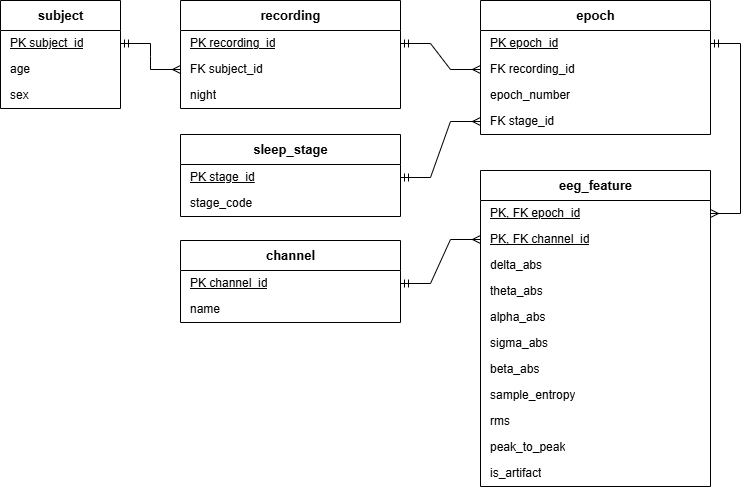

Para mantener la integridad de los datos se usan:

- **Claves primarias (PK)** en todas las tablas. En `eeg_feature` es compuesta, (`epoch_id`, `channel_id`): una fila por época y canal.
- **Claves foráneas (FK)** entre las tablas relacionadas.

In [13]:
from src import database_oltp

database_oltp.build_oltp(tidy, recordings)
display(database_oltp.table_counts().to_frame())
show_checks(validation.validate_oltp(tidy))

INFO src.database_oltp: OLTP creada: data/database/sleep_oltp.sqlite


,rows
subject,18
recording,36
channel,2
sleep_stage,5
epoch,41397
eeg_feature,82794


  ✔ PRAGMA foreign_key_check sin violaciones
  ✔ recording: 36 filas
  ✔ epoch: 41397 filas = épocas con etapa puntuada de la tidy
  ✔ eeg_feature: 82794 filas = filas con etapa puntuada de la tidy
  ✔ Potencia relativa recalculada en la vista coincide (max |dif| = 2.1e-15)


> **Prompt 12.** *Armá el almacén SQLite en esquema estrella, cargado desde la base transaccional y no desde los Parquet. El grano es una época de un canal en un registro, con 3 dimensiones: etapa, registro y canal. El sujeto y el grupo etario van como jerarquía dentro de registro. En la tabla de hechos guardá también la potencia total y las relativas, para que las consultas no tengan que calcularlas. Sumá además el tiempo desde el inicio del sueño y la marca de outlier de Tukey, para poder incluir o excluir esas épocas en el dashboard.*

## Data Warehouse

El almacén (`data/database/sleep_dw.sqlite`) se construye con un ETL que lee del OLTP (no del Parquet).

1. **Extract:** una consulta SQL que une las vistas del OLTP.
2. **Transform:** se arman las dimensiones con sus claves subrogadas y se calcula el tiempo desde el inicio del sueño y la marca de outlier de Tukey.
3. **Load:** primero se cargan las dimensiones y después los hechos.

In [14]:
from src import database_dw

dw_counts = database_dw.build_dw()
display(pd.Series(dw_counts, name="filas").to_frame())
show_checks(validation.validate_dw())

INFO src.database_dw: DW creado: data/database/sleep_dw.sqlite


,filas
dim_recording,36
dim_channel,2
dim_sleep_stage,5
fact_eeg_epoch,82794


  ✔ DW: PRAGMA foreign_key_check sin violaciones
  ✔ fact_eeg_epoch: 82794 filas = eeg_feature del OLTP


## Esquema estrella

**Grano de `fact_eeg_epoch`:** *una época de 30 segundos de un canal en un registro.*

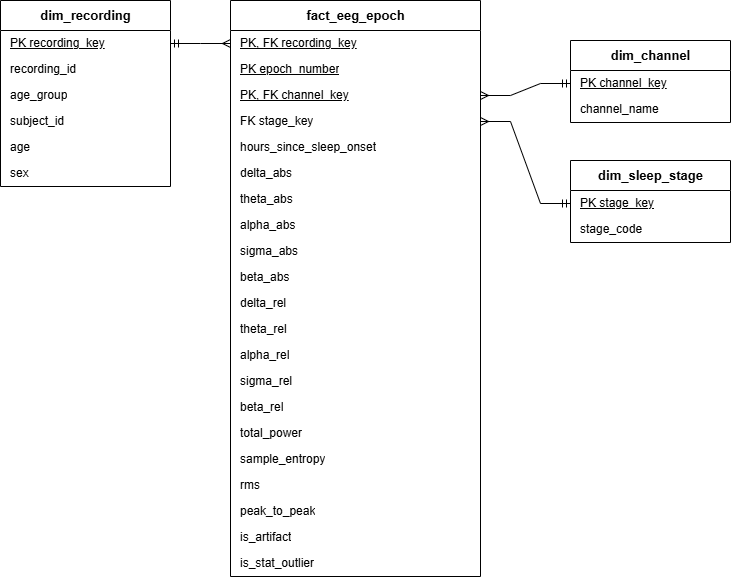

- **Hechos:** la clave primaria es el grano: registro, número de época y canal. La etapa es una FK más. Además,
  el tiempo desde el inicio del sueño, las 14 métricas y las marcas de artefacto y de outlier. La de outlier no
  filtra nada en el análisis: permite que el dashboard incluya o excluya esas épocas.
- **Dimensiones:** `dim_recording` (jerarquía grupo etario → sujeto → registro), `dim_channel` y `dim_sleep_stage`.
- Las dimensiones no se referencian entre sí, como corresponde a una estrella, y usan **claves subrogadas**
  determinísticas.
- **Redundancia deliberada:** se guardan la potencia total y las relativas, que el OLTP calcula en una vista, para
  que las consultas no tengan que recalcularlas.

In [15]:
from IPython.display import Markdown

with database_dw.connect() as conn:
    for table in ["dim_recording", "dim_channel", "dim_sleep_stage"]:
        display(Markdown(f"**{table}**"))
        display(pd.read_sql(f"SELECT * FROM {table}", conn).head(4))
conn.close()

**dim_recording**

,recording_key,recording_id,age_group,subject_id,age,sex
0,1,SC4041,<40,4,34,F
1,2,SC4042,<40,4,34,F
2,3,SC4051,<40,5,28,F
3,4,SC4052,<40,5,28,F


**dim_channel**

,channel_key,channel_name
0,1,Fpz-Cz
1,2,Pz-Oz


**dim_sleep_stage**

,stage_key,stage_code
0,1,W
1,2,N1
2,3,N2
3,4,N3


> **Prompt 13.** *Ahora escribí las consultas SQL sobre el almacén. A partir de la tabla de hechos con sus tres dimensiones, filtrá las épocas con artefacto (`is_artifact = 0`) y ordená las etapas en el orden de las etapas de sueño*
>
> 1. *Para responder la pregunta 1, agrupá por etapa y canal (usa `GROUP BY`) y sacá:*
>    - *El valor de Sample Entropy media, mínima y máxima, junto con la cantidad de épocas;*
>    - *la potencia relativa media de cada banda.*
>
>    *Los canales van por separado, no los promedies entre sí.*
> 2. *Agrupá por etapa, grupo etario y canal, con la cantidad de épocas, la cantidad de sujetos distintos y los promedios de Sample Entropy, delta relativa y sigma relativa. Tienen que dar 30 celdas (3 grupos etarios x 2 canales x 5 bandas).*
> 3. *Para la pregunta 2, las mismas medidas del cubo pero que deje solo N2 (podes usar `WHERE`):*
>    - *una consulta agrupada por grupo etario y canal;*
>    - *otra agrupada por sujeto y canal, con su edad y sexo, para poder graficar un punto por sujeto.*
>
> *Por último, hace una figura del cubo con esos valores, con vista en 3D*

## Consultas SQL

Las 5 consultas están en `src/queries.py` y se ejecutan con `queries.run_query("nombre")`. Todas excluyen los
artefactos.

| # | Nombre | Qué devuelve |
|---|---|---|
| 1 | `sample_entropy_by_stage` | Sample Entropy media, mínima y máxima por etapa y canal (pregunta 1) |
| 2 | `relative_band_power_by_stage` | Potencia relativa de cada banda por etapa y canal (pregunta 1) |
| 3 | `cube` | El cubo completo: una celda por etapa × grupo etario × canal |
| 4 | `n2_by_age_group` | El cubo con la etapa fija en N2, por grupo etario y canal (pregunta 2) |
| 5 | `n2_by_subject` | Dentro de N2, un valor por sujeto en lugar de por grupo etario (pregunta 2) |

A continuación se muestra un ejemplo de una consulta: Sample Entropy por etapa de sueño.

In [16]:
from src import queries

print(queries.QUERIES["sample_entropy_by_stage"])


        SELECT st.stage_code, c.channel_name AS channel,
               COUNT(f.sample_entropy) AS n, AVG(f.sample_entropy) AS mean_sample_entropy,
               MIN(f.sample_entropy) AS min_value, MAX(f.sample_entropy) AS max_value
        
FROM fact_eeg_epoch f
JOIN dim_recording   r  ON r.recording_key  = f.recording_key
JOIN dim_channel     c  ON c.channel_key    = f.channel_key
JOIN dim_sleep_stage st ON st.stage_key     = f.stage_key
 WHERE f.is_artifact = 0
        GROUP BY st.stage_code, st.stage_key, c.channel_name
        ORDER BY st.stage_key, channel


En el siguiente ejemplo se muestra la ejecución de la consulta anterior.

In [17]:
# 1. Sample Entropy promedio por etapa
q1 = queries.run_query("sample_entropy_by_stage")
display(q1.round(3))

,stage_code,channel,n,mean_sample_entropy,min_value,max_value
0,W,Fpz-Cz,11174,0.977,0.030,2.069
1,W,Pz-Oz,11233,1.291,0.041,2.038
2,N1,Fpz-Cz,4029,1.021,0.067,1.925
3,N1,Pz-Oz,4024,0.998,0.154,1.879
4,N2,Fpz-Cz,16635,0.798,0.062,1.674
5,N2,Pz-Oz,16619,0.816,0.154,1.856
6,N3,Fpz-Cz,2610,0.556,0.274,1.175
7,N3,Pz-Oz,2608,0.596,0.134,1.554
8,REM,Fpz-Cz,6849,0.996,0.083,1.874
9,REM,Pz-Oz,6846,1.007,0.106,1.608


## Cubo

Las 3 dimensiones forman un cubo de **5 etapas × 3 grupos etarios × 2 canales = 30 celdas**: la anchura es la
etapa, la altura, el grupo etario, y la profundidad, el canal.

In [18]:
cube = queries.run_query("cube")
print(f"Celdas del cubo: {len(cube)} · sujetos por celda: {cube['n_subjects'].min()}–{cube['n_subjects'].max()}")
# En este ejemplo se muestran los valores de sigma_rel para la etapa N2, pero se puede cambiar a cualquier otra etapa y variable.
plots.cube_figure(cube, "sigma_rel", "N2").show()

Celdas del cubo: 30 · sujetos por celda: 5–6


In [19]:
print("N2 por grupo etario y canal")
display(queries.run_query("n2_by_age_group").round(3))
print("Detalle por sujeto en N2")
n2_subjects = queries.run_query("n2_by_subject")
display(n2_subjects.round(3).head(6))

N2 por grupo etario y canal


,age_group,channel,n,n_subjects,sample_entropy,delta_rel,sigma_rel
0,<40,Fpz-Cz,5765,6,0.829,0.761,0.059
1,<40,Pz-Oz,5754,6,0.822,0.736,0.056
2,40-64,Fpz-Cz,5888,6,0.842,0.793,0.037
3,40-64,Pz-Oz,5892,6,0.826,0.744,0.032
4,65+,Fpz-Cz,4982,6,0.709,0.852,0.017
5,65+,Pz-Oz,4973,6,0.798,0.760,0.021


Detalle por sujeto en N2


,age_group,subject_id,age,sex,channel,n,n_subjects,sample_entropy,delta_rel,sigma_rel
0,<40,10,26,M,Fpz-Cz,1278,1,0.753,0.813,0.049
1,<40,10,26,M,Pz-Oz,1278,1,0.799,0.799,0.038
2,<40,14,27,M,Fpz-Cz,790,1,0.876,0.745,0.063
3,<40,14,27,M,Pz-Oz,790,1,0.850,0.707,0.065
4,<40,5,28,F,Fpz-Cz,833,1,0.815,0.735,0.046
5,<40,5,28,F,Pz-Oz,833,1,0.773,0.691,0.046


> **Prompt 14.** *Con la librería Plotly, y leyendo solo del almacén (sin artefactos), hace los siguientes gráficos:*
>
> 1. *Para la pregunta 1, sobre complejidad: un violín de Sample Entropy por etapa, con los dos canales por separado, para ver la forma de la distribución y no solo el promedio.*
> 2. *Para la pregunta 1b, sobre la actividad espectral: barras de potencia relativa media por banda y etapa usando el canal Pz-Oz. Un panel por banda.*
> 3. *Para la pregunta 2: sigma relativa en N2 contra la edad, con un punto por sujeto y canal (promediando las dos noches), y mostrá la correlación de Spearman por canal*

## Análisis Exploratorio de Datos

Todas las figuras leen del almacén y responden una pregunta concreta.

In [20]:
obs = queries.load_observations()
print(f"Observaciones cargadas desde el DW: {len(obs):,}")

Observaciones cargadas desde el DW: 82,794


### Pregunta 1: ¿cómo varía el EEG entre etapas?

**¿Cómo cambia la Sample Entropy entre etapas, y es igual en ambos canales?**

Se toman todas las épocas del almacén de los 18 sujetos y las dos noches, sin los artefactos.
Para cada canal y etapa se dibuja la distribución de los valores de entropía (Sample Entropy) de todas esas épocas: el gráfico de violín muestra la forma de la distribución, y la caja interna, la mediana y los cuartiles. Los dos canales se muestran por separado.

In [21]:
plots.metric_by_stage(obs[~obs["is_artifact"]], "sample_entropy").show()

# ¿Se cumple N1 > N2 > N3 en cada sujeto y canal? (solo los que tienen épocas de N3)
by_subject = (obs[~obs["is_artifact"]].groupby(["subject_id", "channel", "stage_code"])["sample_entropy"]
              .mean().unstack().dropna(subset=["N3"]))
ordered = (by_subject["N1"] > by_subject["N2"]) & (by_subject["N2"] > by_subject["N3"])
print(f"Sample Entropy N1 > N2 > N3 en {ordered.sum()} de {len(ordered)} combinaciones de sujeto y canal")

Sample Entropy N1 > N2 > N3 en 32 de 32 combinaciones de sujeto y canal


**¿Qué bandas dominan cada etapa? (canal posterior, donde el alfa de vigilia es más visible)**

Para cada etapa y canal se promedia la potencia relativa de cada banda sobre todas las épocas, con todos los sujetos juntos y sin artefactos. Cada panel es una banda y cada barra, una etapa; dentro de una misma etapa, las cinco bandas suman 1. Se muestra el canal Pz-Oz.

In [22]:
rel = queries.run_query("relative_band_power_by_stage")
display(rel.round(2))
plots.band_power_by_stage(rel, "Pz-Oz").show()

,stage_code,channel,n,delta,theta,alpha,sigma,beta
0,W,Fpz-Cz,11174,0.73,0.08,0.07,0.03,0.09
1,W,Pz-Oz,11233,0.50,0.12,0.18,0.05,0.14
2,N1,Fpz-Cz,4029,0.71,0.12,0.07,0.03,0.06
3,N1,Pz-Oz,4024,0.64,0.18,0.11,0.03,0.05
4,N2,Fpz-Cz,16635,0.80,0.10,0.04,0.04,0.02
5,N2,Pz-Oz,16619,0.75,0.15,0.05,0.04,0.02
6,N3,Fpz-Cz,2610,0.92,0.05,0.02,0.01,0.00
7,N3,Pz-Oz,2608,0.87,0.08,0.02,0.01,0.01
8,REM,Fpz-Cz,6849,0.74,0.13,0.06,0.03,0.05
9,REM,Pz-Oz,6846,0.66,0.18,0.10,0.03,0.04


### Pregunta 2: ¿cómo difiere la potencia sigma en N2 entre personas de distintas edades?

Para cada sujeto y canal se promedia la potencia relativa sigma de sus épocas de N2 de las dos noches, sin artefactos. Cada punto es un sujeto en un canal. La relación con la edad se resume con la correlación de Spearman.

In [23]:
plots.sigma_vs_age(n2_subjects).show()
for channel, group in n2_subjects.groupby("channel"):
    print(f"Spearman edad ~ sigma en N2, {channel}: ρ = {group['age'].corr(group['sigma_rel'], method='spearman'):.2f} "
          f"(n = {len(group)} sujetos)")

Spearman edad ~ sigma en N2, Fpz-Cz: ρ = -0.86 (n = 18 sujetos)
Spearman edad ~ sigma en N2, Pz-Oz: ρ = -0.76 (n = 18 sujetos)


- **A mayor edad, menor potencia relativa sigma en N2:** en Fpz-Cz, 0,059 en <40, 0,037 en 40–64 y 0,017 en 65+ (Spearman
  −0,86 en Fpz-Cz y −0,76 en Pz-Oz). Este resultado es coherente con la disminución de husos de sueño que describe la literatura.

> **Prompt 15.** *Hacé un dashboard en Streamlit que lea solo del almacén y que permita visualizar los resultados que responden a las dos preguntas. Ponele un titulo a cada sección. Indicame como ejecutar el dashboard.*

## Dashboard

Se creó un dashboard utilizando Streamlit, que lee solo datos del almacén. En el dashboard se pueden encontrar filtros por grupo etario, sujeto, registro, canal y etapa, casillas para incluir artefactos y outliers, y está organizado por las dos preguntas del trabajo.

Para ejecutar el dashboard se tiene que ejecutar por consola y desde la carpeta del trabajo (`TP/tpf`) el siguiente comando: `streamlit run src/dashboard.py` 

## Resultados principales

Se analizaron 36 registros (18 sujetos × 2 noches): 41 596 épocas, unas 347 h de sueño, y 83 192 observaciones.

**Pregunta 1.** Cuanto más profundo es el sueño NREM, más lento y regular es el EEG:

- Los valores de Sample Entropy bajan de N1 a N3 en las 32 combinaciones de sujeto y canal (en Pz-Oz: 1,00 en N1, 0,82 en N2 y 0,60 en N3). REM queda cerca de N1 (1,01).
- La potencia relativa en delta es máxima en N3: 0,92 en Fpz-Cz y 0,88 en Pz-Oz.
- En vigilia, el alfa es máximo en Pz-Oz (0,18). En Fpz-Cz la vigilia es menos compleja, lo que es compatible con la actividad ocular.

**Pregunta 2.** A mayor edad, menos potencia relativa sigma en N2 (en Fpz-Cz, 0,059 en <40 frente a 0,017 en 65+).

## Limitaciones

- **Muestra pequeña:** 18 sujetos sanos de un único estudio, 3 por sexo y grupo etario; no se pueden separar la edad, el sexo y la variabilidad individual.
- **Sin inferencia estadística:** las épocas de una noche no son independientes; haría falta un modelo mixto.
- **Dos canales bipolares:** no permiten análisis topográfico, y Fpz-Cz es sensible a la actividad ocular.
- **Artefactos sutiles** (oculares, musculares) no se detectan con criterios físicos.

## Conclusiones

El pipeline lleva datos públicos de EEG de sueño, de forma reproducible, desde los archivos EDF hasta una base
transaccional en 3NF, un almacén en estrella y un dashboard, con cada decisión de calidad documentada y sin imputar valores ni
borrar observaciones: los artefactos y los outliers solo se marcan.

Sobre la **pregunta 1**, cuanto más profundo es el sueño NREM, más potencia hay en ondas lentas y menor es la
complejidad del EEG. Sobre la **pregunta 2**, la potencia sigma de N2 es menor en las personas de más edad. Ambos
resultados coinciden con la fisiología conocida del sueño, lo que es una buena señal de que el pipeline procesa correctamente los datos.

**Trabajo futuro:** para almacenar **señal EEG continua** (por ejemplo, de *wearables* de sueño) convendría una base
de series temporales como **TimescaleDB**, con particionado por tiempo y compresión. Para las features por época de
este trabajo, SQLite alcanza.